# Credit Risk Assessment & Portfolio Monitoring

### Project Overview

This project analyzes historical consumer credit data to identify risk patterns, assess credit portfolio composition, and develop data-driven recommendations for portfolio monitoring.

Using Python, the analysis explores relationships between credit outcomes and borrower characteristics, loan amounts, loan durations, credit history, and loan purposes.

### Dataset

**Source:** UCI South German Credit Dataset

- **Observations:** 1,000 credit records
- **Features:** 20 explanatory variables
- **Target Variable:** `kredit`
  - `0`: Bad Credit
  - `1`: Good Credit

The dataset is a historical benchmark and does not represent a current banking portfolio.

### Tools & Technologies

- **Python**
- **Pandas:** Data cleaning, segmentation, and aggregation
- **Matplotlib & Seaborn:** Data visualization
- **Jupyter Notebook:** Analysis and documentation

### Project Objectives

1. Evaluate overall credit portfolio risk.
2. Identify borrower and loan characteristics associated with higher Bad Credit rates.
3. Analyze risk concentration across loan segments.
4. Calculate portfolio monitoring KPIs.
5. Develop actionable business recommendations based on analytical findings.

### Methodology

The project follows five analytical stages:

1. Data Quality Assessment
2. Exploratory Data Analysis
3. Credit Risk Segmentation
4. Portfolio Exposure Analysis
5. Business Insights & Recommendations

In [1]:
%pip install ucimlrepo pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:

import pandas as pd

df = pd.read_csv("SouthGermanCredit.asc", sep=r"\s+")


In [3]:
df.head()

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


In [4]:
df.shape

(1000, 21)

In [5]:
df.columns.tolist()

['laufkont',
 'laufzeit',
 'moral',
 'verw',
 'hoehe',
 'sparkont',
 'beszeit',
 'rate',
 'famges',
 'buerge',
 'wohnzeit',
 'verm',
 'alter',
 'weitkred',
 'wohn',
 'bishkred',
 'beruf',
 'pers',
 'telef',
 'gastarb',
 'kredit']

In [6]:
df["kredit"].value_counts()

kredit
1    700
0    300
Name: count, dtype: int64

In [7]:
df["kredit"].value_counts(normalize=True) * 100

kredit
1    70.0
0    30.0
Name: proportion, dtype: float64

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   laufkont  1000 non-null   int64
 1   laufzeit  1000 non-null   int64
 2   moral     1000 non-null   int64
 3   verw      1000 non-null   int64
 4   hoehe     1000 non-null   int64
 5   sparkont  1000 non-null   int64
 6   beszeit   1000 non-null   int64
 7   rate      1000 non-null   int64
 8   famges    1000 non-null   int64
 9   buerge    1000 non-null   int64
 10  wohnzeit  1000 non-null   int64
 11  verm      1000 non-null   int64
 12  alter     1000 non-null   int64
 13  weitkred  1000 non-null   int64
 14  wohn      1000 non-null   int64
 15  bishkred  1000 non-null   int64
 16  beruf     1000 non-null   int64
 17  pers      1000 non-null   int64
 18  telef     1000 non-null   int64
 19  gastarb   1000 non-null   int64
 20  kredit    1000 non-null   int64
dtypes: int64(21)
memory usage: 164.2 KB


In [9]:
df.isnull().sum()

laufkont    0
laufzeit    0
moral       0
verw        0
hoehe       0
sparkont    0
beszeit     0
rate        0
famges      0
buerge      0
wohnzeit    0
verm        0
alter       0
weitkred    0
wohn        0
bishkred    0
beruf       0
pers        0
telef       0
gastarb     0
kredit      0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df[["alter", "hoehe", "laufzeit"]].describe()

,alter,hoehe,laufzeit
count,1000.00000,1000.00000,1000.000000
mean,35.54200,3271.24800,20.903000
std,11.35267,2822.75176,12.058814
min,19.00000,250.00000,4.000000
25%,27.00000,1365.50000,12.000000
50%,33.00000,2319.50000,18.000000
75%,42.00000,3972.25000,24.000000
max,75.00000,18424.00000,72.000000


<Axes: >

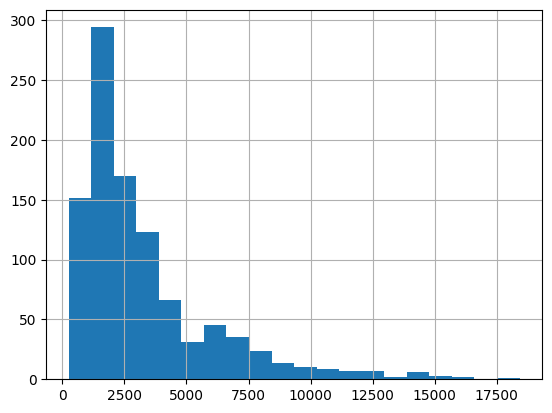

In [12]:
df["hoehe"].hist(bins=20)

In [13]:
df.groupby("kredit")["hoehe"].mean()

kredit
0    3938.126667
1    2985.442857
Name: hoehe, dtype: float64

In [14]:
df.groupby("kredit")["hoehe"].median()

kredit
0    2574.5
1    2244.0
Name: hoehe, dtype: float64

In [15]:
df["amount_group"] = pd.qcut(df["hoehe"], q=4)

In [16]:
df[["hoehe", "amount_group"]].head()

,hoehe,amount_group
0,1049,"(249.999, 1365.5]"
1,2799,"(2319.5, 3972.25]"
2,841,"(249.999, 1365.5]"
3,2122,"(1365.5, 2319.5]"
4,2171,"(1365.5, 2319.5]"


In [17]:
df["amount_group"].value_counts().sort_index()

amount_group
(249.999, 1365.5]     250
(1365.5, 2319.5]      250
(2319.5, 3972.25]     250
(3972.25, 18424.0]    250
Name: count, dtype: int64

In [18]:
(1 - df.groupby("amount_group")["kredit"].mean()) * 100

amount_group
(249.999, 1365.5]     30.8
(1365.5, 2319.5]      24.8
(2319.5, 3972.25]     22.4
(3972.25, 18424.0]    42.0
Name: kredit, dtype: float64

In [19]:
df["laufzeit"].value_counts().sort_index()

laufzeit
4       6
5       1
6      75
7       5
8       7
9      49
10     28
11      9
12    179
13      4
14      4
15     64
16      2
18    113
20      8
21     30
22      2
24    184
26      1
27     13
28      3
30     40
33      3
36     83
39      5
40      1
42     11
45      5
47      1
48     48
54      2
60     13
72      1
Name: count, dtype: int64

In [20]:
df["duration_group"] = pd.cut(df["laufzeit"], bins=[0, 12, 24, 36, 72])

In [21]:
df["duration_group"].value_counts()

duration_group
(12, 24]    411
(0, 12]     359
(24, 36]    143
(36, 72]     87
Name: count, dtype: int64

In [22]:
(1 - df.groupby("duration_group")["kredit"].mean()) * 100

duration_group
(0, 12]     21.169916
(12, 24]    29.683698
(24, 36]    39.860140
(36, 72]    51.724138
Name: kredit, dtype: float64

In [23]:
df.groupby("duration_group")["hoehe"].mean()

duration_group
(0, 12]     1811.401114
(12, 24]    2923.705596
(24, 36]    5273.643357
(36, 72]    7645.758621
Name: hoehe, dtype: float64

In [24]:
(1 - df.groupby(["duration_group", "amount_group"])["kredit"].mean()) * 100

duration_group  amount_group      
(0, 12]         (249.999, 1365.5]      25.862069
                (1365.5, 2319.5]       14.912281
                (2319.5, 3972.25]      11.111111
                (3972.25, 18424.0]     47.058824
(12, 24]        (249.999, 1365.5]      42.666667
                (1365.5, 2319.5]       28.333333
                (2319.5, 3972.25]      21.323529
                (3972.25, 18424.0]     33.750000
(24, 36]        (249.999, 1365.5]       0.000000
                (1365.5, 2319.5]       66.666667
                (2319.5, 3972.25]      29.787234
                (3972.25, 18424.0]     41.250000
(36, 72]        (1365.5, 2319.5]      100.000000
                (2319.5, 3972.25]      53.846154
                (3972.25, 18424.0]     50.684932
Name: kredit, dtype: float64

In [25]:
df.groupby(["duration_group", "amount_group"])["kredit"].value_counts()

duration_group  amount_group        kredit
(0, 12]         (249.999, 1365.5]   1         129
                                    0          45
                (1365.5, 2319.5]    1          97
                                    0          17
                (2319.5, 3972.25]   1          48
                                    0           6
                (3972.25, 18424.0]  1           9
                                    0           8
(12, 24]        (249.999, 1365.5]   1          43
                                    0          32
                (1365.5, 2319.5]    1          86
                                    0          34
                (2319.5, 3972.25]   1         107
                                    0          29
                (3972.25, 18424.0]  1          53
                                    0          27
(24, 36]        (249.999, 1365.5]   1           1
                (1365.5, 2319.5]    0          10
                                    1           5
       

In [26]:
bad_rate = (1 - df.groupby(["duration_group", "amount_group"], observed=True)["kredit"].mean()) * 100

bad_rate.unstack()

amount_group,"(249.999, 1365.5]","(1365.5, 2319.5]","(2319.5, 3972.25]","(3972.25, 18424.0]"
duration_group,,,,
"(0, 12]",25.862069,14.912281,11.111111,47.058824
"(12, 24]",42.666667,28.333333,21.323529,33.750000
"(24, 36]",0.000000,66.666667,29.787234,41.250000
"(36, 72]",NaN,100.000000,53.846154,50.684932


In [27]:
bad_rate_table = bad_rate.unstack()

In [28]:
sample_size = df.groupby(["duration_group", "amount_group"], observed=True)["kredit"].count()

sample_size.unstack()

amount_group,"(249.999, 1365.5]","(1365.5, 2319.5]","(2319.5, 3972.25]","(3972.25, 18424.0]"
duration_group,,,,
"(0, 12]",174.0,114.0,54.0,17.0
"(12, 24]",75.0,120.0,136.0,80.0
"(24, 36]",1.0,15.0,47.0,80.0
"(36, 72]",NaN,1.0,13.0,73.0


In [29]:
sample_size_table = sample_size.unstack()

In [30]:
import seaborn as sns

<Axes: xlabel='amount_group', ylabel='duration_group'>

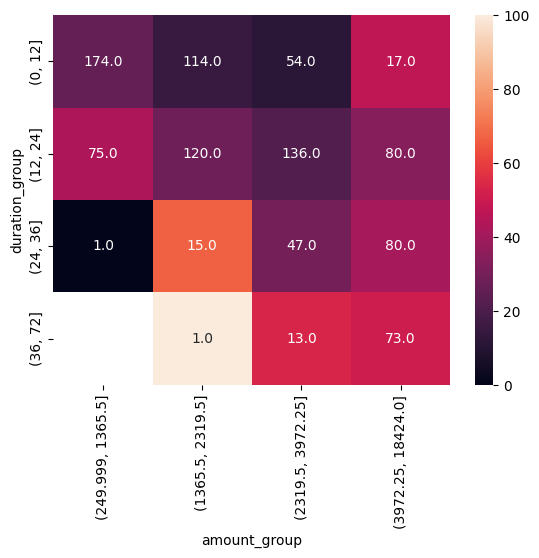

In [31]:
sns.heatmap(bad_rate_table, annot=sample_size_table, fmt=".1f")

In [32]:
labels = bad_rate_table.copy()

In [33]:
labels = labels.astype(object)

In [34]:
labels = bad_rate_table.map(lambda x: f"{x:.1f}%")

In [35]:
labels

amount_group,"(249.999, 1365.5]","(1365.5, 2319.5]","(2319.5, 3972.25]","(3972.25, 18424.0]"
duration_group,,,,
"(0, 12]",25.9%,14.9%,11.1%,47.1%
"(12, 24]",42.7%,28.3%,21.3%,33.8%
"(24, 36]",0.0%,66.7%,29.8%,41.2%
"(36, 72]",nan%,100.0%,53.8%,50.7%


In [36]:
labels = labels + "\nn=" + sample_size_table.map(lambda x: f"{x:.0f}")

In [37]:
labels

amount_group,"(249.999, 1365.5]","(1365.5, 2319.5]","(2319.5, 3972.25]","(3972.25, 18424.0]"
duration_group,,,,
"(0, 12]",25.9%\nn=174,14.9%\nn=114,11.1%\nn=54,47.1%\nn=17
"(12, 24]",42.7%\nn=75,28.3%\nn=120,21.3%\nn=136,33.8%\nn=80
"(24, 36]",0.0%\nn=1,66.7%\nn=15,29.8%\nn=47,41.2%\nn=80
"(36, 72]",nan%\nn=nan,100.0%\nn=1,53.8%\nn=13,50.7%\nn=73


In [38]:
print(labels.iloc[0, 0])

25.9%
n=174


<Axes: xlabel='amount_group', ylabel='duration_group'>

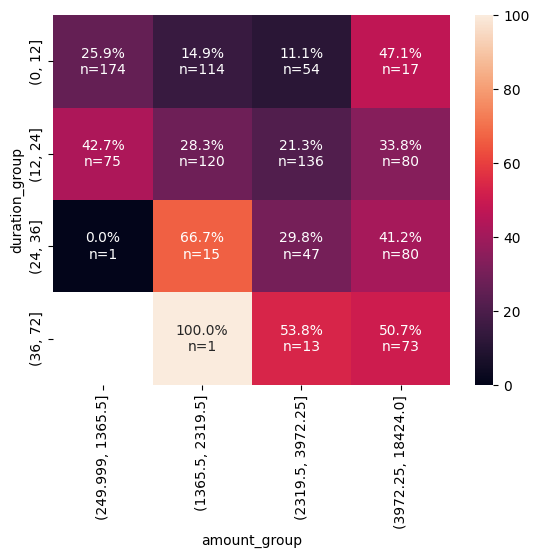

In [39]:
sns.heatmap(bad_rate_table, annot=labels, fmt="")

In [40]:
import matplotlib.pyplot as plt

Text(50.722222222222214, 0.5, 'Loan Duration (Months)')

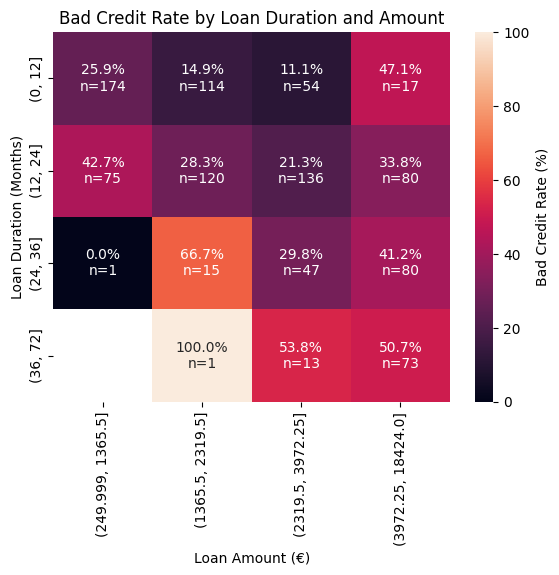

In [41]:
sns.heatmap(bad_rate_table, annot=labels, fmt="", cbar_kws={"label": "Bad Credit Rate (%)"})
plt.title("Bad Credit Rate by Loan Duration and Amount")
plt.xlabel("Loan Amount (€)")
plt.ylabel("Loan Duration (Months)")

In [42]:
df["age_group"] = pd.cut(df["alter"], bins=[18, 25, 35, 45, 60, 100])

In [43]:
(1 - df.groupby("age_group", observed=True)["kredit"].mean()) * 100

age_group
(18, 25]     42.105263
(25, 35]     29.722922
(35, 45]     24.017467
(45, 60]     26.618705
(60, 100]    22.222222
Name: kredit, dtype: float64

In [44]:
df.groupby("age_group", observed=True)["kredit"].count()

age_group
(18, 25]     190
(25, 35]     397
(35, 45]     229
(45, 60]     139
(60, 100]     45
Name: kredit, dtype: int64

In [45]:
df["moral"].value_counts().sort_index()

moral
0     40
1     49
2    530
3     88
4    293
Name: count, dtype: int64

In [46]:
(1 - df.groupby("moral")["kredit"].mean()) * 100

moral
0    62.500000
1    57.142857
2    31.886792
3    31.818182
4    17.064846
Name: kredit, dtype: float64

In [47]:
df[df["kredit"] == 0].groupby("moral")["kredit"].count()

moral
0     25
1     28
2    169
3     28
4     50
Name: kredit, dtype: int64

In [48]:
df["verw"].value_counts().sort_index()

verw
0     234
1     103
2     181
3     280
4      12
5      22
6      50
8       9
9      97
10     12
Name: count, dtype: int64

In [49]:
(1 - df.groupby("verw")["kredit"].mean()) * 100

verw
0     38.034188
1     16.504854
2     32.044199
3     22.142857
4     33.333333
5     36.363636
6     44.000000
8     11.111111
9     35.051546
10    41.666667
Name: kredit, dtype: float64

In [50]:
df["hoehe"].sum()

np.int64(3271248)

In [51]:
df[df["kredit"] == 0]["hoehe"].sum()

np.int64(1181438)

In [52]:
df.groupby("kredit")["hoehe"].mean()

kredit
0    3938.126667
1    2985.442857
Name: hoehe, dtype: float64

In [53]:
df.groupby("duration_group", observed=True)["hoehe"].sum()

duration_group
(0, 12]      650293
(12, 24]    1201643
(24, 36]     754131
(36, 72]     665181
Name: hoehe, dtype: int64

In [54]:
df[df["kredit"] == 0].groupby("duration_group", observed=True)["hoehe"].sum()

duration_group
(0, 12]     153583
(12, 24]    373436
(24, 36]    316309
(36, 72]    338110
Name: hoehe, dtype: int64

## Key Findings
### 1. Overall Portfolio Risk
- The dataset contains 1,000 loans, of which 30% are classified as Bad Credit.
- Bad Credit loans account for 36.1% of total credit exposure, indicating that higher loan amounts are disproportionately represented in the Bad Credit category.

### 2. Loan Duration and Credit Risk
- The Bad Credit rate increases from 21.2% for loans with maturities of up to 12 months to 51.7% for loans exceeding 36 months.
- Loans with maturities above 24 months represent 43.4% of total credit exposure but account for 55.4% of Bad Credit exposure.

### 3. Credit History
- Credit history categories show substantial differences in Bad Credit rates, ranging from 17.1% to 62.5%.
- Category 2 contains 56.3% of all Bad Credit loans, highlighting the distinction between individual segment risk and portfolio-level risk concentration.

### 4. Customer Age
- Borrowers aged 19–25 have the highest observed Bad Credit rate (42.1%), compared with the overall portfolio rate of 30%.
- This relationship is descriptive and does not establish that age independently causes credit risk.

### 5. Loan Purpose
- Bad Credit rates vary across loan purpose categories.
- Category 6 has the highest observed Bad Credit rate (44.0%), while category 0 contributes more Bad Credit loans due to its larger customer base.
- Categories with small sample sizes require cautious interpretation.

## Business Recommendations

### 1. Prioritize Monitoring of Long-Term Loans
Loans with maturities exceeding 36 months have the highest observed Bad Credit rate (51.7%).

**Recommendation:** Introduce enhanced portfolio monitoring for long-term loan segments, including regular reviews of their Bad Credit rates and exposure concentration.

### 2. Monitor Risk Concentration, Not Just Default Rates
Loans with maturities above 24 months account for 55.4% of total Bad Credit exposure despite representing only 43.4% of total credit exposure.

**Recommendation:** Track both loan-count-based Bad Credit rates and exposure-based risk indicators to identify segments contributing disproportionately to portfolio risk.

### 3. Incorporate Credit History into Risk Segmentation
Bad Credit rates differ substantially across credit history categories.

**Recommendation:** Use credit history alongside loan amount and duration to develop more detailed risk segments. Validate category definitions before translating findings into operational policies.

### 4. Establish a Portfolio Risk Dashboard
The analysis identifies differences in risk across loan duration, credit amount, credit history, and loan purpose.

**Recommendation:** Develop a monitoring dashboard tracking:
- Overall Bad Credit Rate
- Total Credit Exposure
- Bad Credit Exposure Share
- Bad Credit Rates by Loan Duration
- Bad Credit Exposure by Risk Segment

### 5. Validate Findings Before Operational Implementation
The analysis is based on a historical credit dataset and identifies associations rather than causal relationships.

**Recommendation:** Validate the observed patterns using more recent and representative lending data before implementing credit policy changes. Assess model fairness and regulatory requirements before using customer characteristics in automated decisions.